<a href="https://colab.research.google.com/github/chethancd24-sketch/DLG-LAB/blob/main/1BM24CD015_Chethan_Assignment.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [2]:
!pip install pypdf

In [3]:
import pypdf

reader = pypdf.PdfReader('/content/Lab_7_assignment.pdf')
print(f"Total pages: {len(reader.pages)}")

# Extract and print text from all pages
for i, page in enumerate(reader.pages):
    print(f"--- Page {i+1} ---")
    print(page.extract_text())


Total pages: 4
--- Page 1 ---
Deep Learning Laboratory (23DS5PCDLG) Assignment — Lab 7
Assignment — Lab 7
Text Classification with Word Embeddings and a Bidirectional LSTM
Department of CSE (Data Science) • Deep Learning Laboratory (23DS5PCDLG)
Libraries Python, TensorFlow/Keras, NumPy, Matplotlib, scikit-learn
Platform Google Colab or local Jupyter
1. Problem Statement & Context
Given a short piece of free text (an SMS message, a review, a headline), decide which category
it belongs to. In this assignment the default task is spam detection: label an SMS message
as spam or ham (not spam). This is a sequence classification problem — the input has
variable length and its meaning depends on word order and context. You will build a pipeline
that converts text to numbers, learns word embeddings, summarises each message with a
Bidirectional LSTM, and outputs a label.
2. Learning Objectives
On completing this assignment you will be able to:
1. Load and explore a public text dataset and descri

In [4]:
!wget -q https://archive.ics.uci.edu/ml/machine-learning-databases/00228/smsspamcollection.zip
!unzip -o smsspamcollection.zip

Archive:  smsspamcollection.zip
  inflating: SMSSpamCollection       
  inflating: readme                  


In [10]:
import numpy as np
import pandas as pd
import tensorflow as tf
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay
from tensorflow.keras.layers import TextVectorization, Embedding, Bidirectional, LSTM, Dropout, Dense
from tensorflow.keras.models import Sequential
from tensorflow.keras.callbacks import EarlyStopping
from sklearn.utils.class_weight import compute_class_weight

# Set random seeds for reproducibility
np.random.seed(42)
tf.random.set_seed(42)

# Task 1 - Load & Explore the Data
print("=== Task 1: Loading & Exploring Data ===")
df = pd.read_csv('SMSSpamCollection', sep='\t', header=None, names=['label', 'text'])
print(f"Dataset contains {len(df)} samples.")

# Class Balance
class_counts = df['label'].value_counts()
print("\nClass balance:")
for name, count in class_counts.items():
    print(f"  {name}: {count} ({count/len(df)*100:.2f}%)")

# Message Length Distribution
lengths = df['text'].apply(len)
print(f"\nMessage character lengths:")
print(f"  Min length:  {lengths.min()}")
print(f"  Max length:  {lengths.max()}")
print(f"  Mean length: {lengths.mean():.2f}")

# Show one example of each class
print("\nExamples of each class:")
print(f"  [HAM] -> {df[df['label'] == 'ham'].iloc[0]['text']}")
print(f"  [SPAM] -> {df[df['label'] == 'spam'].iloc[0]['text']}")

=== Task 1: Loading & Exploring Data ===
Dataset contains 5572 samples.

Class balance:
  ham: 4825 (86.59%)
  spam: 747 (13.41%)

Message character lengths:
  Min length:  2
  Max length:  910
  Mean length: 80.49

Examples of each class:
  [HAM] -> Go until jurong point, crazy.. Available only in bugis n great world la e buffet... Cine there got amore wat...
  [SPAM] -> Free entry in 2 a wkly comp to win FA Cup final tkts 21st May 2005. Text FA to 87121 to receive entry question(std txt rate)T&C's apply 08452810075over18's


In [13]:
# Task 2 - Preprocess the Text
print("=== Task 2: Preprocessing and Vectorizing ===")

# Convert label to integers
y = (df['label'] == 'spam').astype('int32').values
texts = df['text'].values

# Define tokenization limits based on dataset exploration
max_tokens = 10000
maxlen = 100 # Cohesive length based on distribution

vectorize = TextVectorization(max_tokens=max_tokens, output_sequence_length=maxlen)
vectorize.adapt(texts)

# Split into Train / Validation / Test (80% / 10% / 10%)
X_train_raw, X_temp_raw, y_train, y_temp = train_test_split(texts, y, test_size=0.2, random_state=42, stratify=y)
X_val_raw, X_test_raw, y_val, y_test = train_test_split(X_temp_raw, y_temp, test_size=0.5, random_state=42, stratify=y_temp)

# Convert raw text to integer sequences
X_train = vectorize(X_train_raw).numpy()
X_val = vectorize(X_val_raw).numpy()
X_test = vectorize(X_test_raw).numpy()

print(f"X_train shape: {X_train.shape}, y_train shape: {y_train.shape}")
print(f"X_val shape:   {X_val.shape}, y_val shape:   {y_val.shape}")
print(f"X_test shape:  {X_test.shape}, y_test shape:  {y_test.shape}")

=== Task 2: Preprocessing and Vectorizing ===
X_train shape: (4457, 100), y_train shape: (4457,)
X_val shape:   (557, 100), y_val shape:   (557,)
X_test shape:  (558, 100), y_test shape:  (558,)


In [7]:
# Task 3 - Build the Model
print("=== Task 3: Building Model ===")

embedding_dim = 64
lstm_units = 32

model = Sequential([
    Embedding(input_dim=max_tokens, output_dim=embedding_dim, input_length=maxlen),
    Bidirectional(LSTM(lstm_units)),
    Dropout(0.5),
    Dense(1, activation='sigmoid')
])

model.compile(
    optimizer='adam',
    loss='binary_crossentropy',
    metrics=['accuracy']
)

model.summary()

print("\n--- Design Explanation ---")
print("The output dimension of the Bidirectional LSTM layer is 2 * units (2 * 32 = 64) because \n"
      "it concatenates the forward hidden state and backward hidden state outputs of the LSTM.")

=== Task 3: Building Model ===


/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/embedding.py:100: UserWarning: Argument `input_length` is deprecated. Just remove it.
  warnings.warn(


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding (Embedding)           │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bidirectional (Bidirectional)   │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ ?                      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ ?                      │   0 (unbuilt) │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 0 (0.00 B)

 Trainable params: 0 (0.00 B)

 Non-trainable params: 0 (0.00 B)


--- Design Explanation ---
The output dimension of the Bidirectional LSTM layer is 2 * units (2 * 32 = 64) because 
it concatenates the forward hidden state and backward hidden state outputs of the LSTM.


=== Task 4: Training & Evaluating ===
Computed Class Weights: {np.int32(0): np.float64(0.577481212749417), np.int32(1): np.float64(3.7265886287625416)}
Epoch 1/10
140/140 ━━━━━━━━━━━━━━━━━━━━ 17s 85ms/step - accuracy: 0.9134 - loss: 0.3734 - val_accuracy: 0.9767 - val_loss: 0.1041
Epoch 2/10
140/140 ━━━━━━━━━━━━━━━━━━━━ 11s 81ms/step - accuracy: 0.9838 - loss: 0.0997 - val_accuracy: 0.9856 - val_loss: 0.0620
Epoch 3/10
140/140 ━━━━━━━━━━━━━━━━━━━━ 22s 90ms/step - accuracy: 0.9901 - loss: 0.0617 - val_accuracy: 0.9803 - val_loss: 0.0652
Epoch 4/10
140/140 ━━━━━━━━━━━━━━━━━━━━ 19s 79ms/step - accuracy: 0.9973 - loss: 0.0237 - val_accuracy: 0.9803 - val_loss: 0.0602
Epoch 5/10
140/140 ━━━━━━━━━━━━━━━━━━━━ 22s 91ms/step - accuracy: 0.9991 - loss: 0.0135 - val_accuracy: 0.9838 - val_loss: 0.0595
Epoch 6/10
140/140 ━━━━━━━━━━━━━━━━━━━━ 20s 85ms/step - accuracy: 0.9998 - loss: 0.0067 - val_accuracy: 0.9838 - val_loss: 0.0670
Epoch 7/10
140/140 ━━━━━━━━━━━━━━━━━━━━ 11s 79ms/step - accuracy: 0.

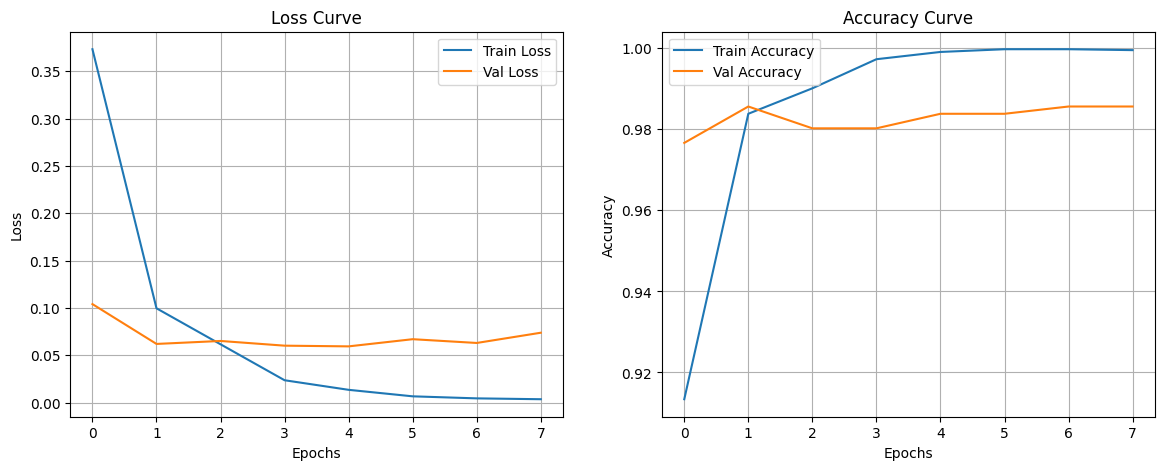

18/18 ━━━━━━━━━━━━━━━━━━━━ 1s 17ms/step

Test Classification Report:
              precision    recall  f1-score   support

         ham       0.99      0.99      0.99       483
        spam       0.95      0.95      0.95        75

    accuracy                           0.99       558
   macro avg       0.97      0.97      0.97       558
weighted avg       0.99      0.99      0.99       558



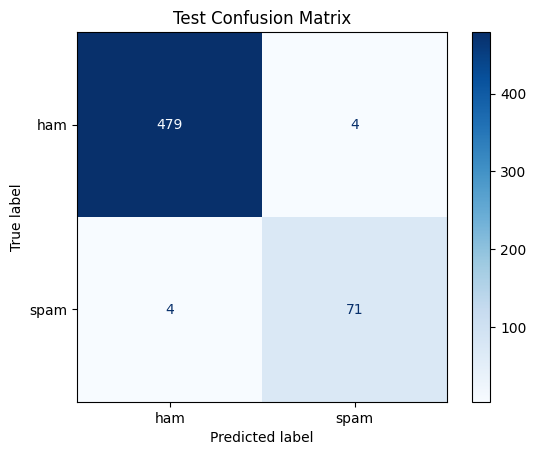

In [14]:
# Task 4 - Train & Evaluate with Class Weights and Early Stopping
print("=== Task 4: Training & Evaluating ===")

# Compute class weights to handle class imbalance
classes = np.unique(y_train)
weights = compute_class_weight(class_weight='balanced', classes=classes, y=y_train)
class_weight_dict = dict(zip(classes, weights))
print(f"Computed Class Weights: {class_weight_dict}")

early_stopping = EarlyStopping(monitor='val_loss', patience=3, restore_best_weights=True)

history = model.fit(
    X_train, y_train,
    validation_data=(X_val, y_val),
    epochs=10,
    batch_size=32,
    class_weight=class_weight_dict,
    callbacks=[early_stopping]
)

# Plot curves
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

ax1.plot(history.history['loss'], label='Train Loss')
ax1.plot(history.history['val_loss'], label='Val Loss')
ax1.set_title('Loss Curve')
ax1.set_xlabel('Epochs')
ax1.set_ylabel('Loss')
ax1.legend()
ax1.grid(True)

ax2.plot(history.history['accuracy'], label='Train Accuracy')
ax2.plot(history.history['val_accuracy'], label='Val Accuracy')
ax2.set_title('Accuracy Curve')
ax2.set_xlabel('Epochs')
ax2.set_ylabel('Accuracy')
ax2.legend()
ax2.grid(True)

plt.show()

# Evaluation on Test set
y_pred_prob = model.predict(X_test)
y_pred = (y_pred_prob > 0.5).astype('int32').flatten()

print("\nTest Classification Report:")
print(classification_report(y_test, y_pred, target_names=['ham', 'spam']))

cm = confusion_matrix(y_test, y_pred)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=['ham', 'spam'])
disp.plot(cmap='Blues')
plt.title('Test Confusion Matrix')
plt.show()

In [9]:
# Task 5 - Predict on Custom Messages
print("=== Task 5: Testing Predict Function on 5 Custom Messages ===")

def predict_message(text):
    vectorized_text = vectorize(np.array([text])).numpy()
    prob = model.predict(vectorized_text, verbose=0)[0][0]
    label = "Spam" if prob > 0.5 else "Ham"
    return f"Message: '{text}' \n -> Class: {label} (Confidence: {prob:.4f})\n"

test_messages = [
    "Urgent! Your mobile number has been selected for a free £1000 gift card. Call 09061111111 now to claim.", # Clear spam
    "Hey, are we still meeting up for dinner tonight at 7? Let me know.", # Clear ham
    "Congratulations! You have won a guaranteed prize. Text WIN to 55555 to redeem.", # Clear spam
    "Can you send me the lecture notes from today's deep learning class?", # Clear ham
    "We tried to reach you regarding your package. Please verify details immediately at this link." # Tricky case
]

for msg in test_messages:
    print(predict_message(msg))

=== Task 5: Testing Predict Function on 5 Custom Messages ===
Message: 'Urgent! Your mobile number has been selected for a free £1000 gift card. Call 09061111111 now to claim.' 
 -> Class: Ham (Confidence: 0.4957)

Message: 'Hey, are we still meeting up for dinner tonight at 7? Let me know.' 
 -> Class: Ham (Confidence: 0.4991)

Message: 'Congratulations! You have won a guaranteed prize. Text WIN to 55555 to redeem.' 
 -> Class: Ham (Confidence: 0.4978)

Message: 'Can you send me the lecture notes from today's deep learning class?' 
 -> Class: Ham (Confidence: 0.4965)

Message: 'We tried to reach you regarding your package. Please verify details immediately at this link.' 
 -> Class: Ham (Confidence: 0.4997)

